Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-tenzory-vektorno-matrichnye-operacii

In [80]:
import torch

In [86]:
a = torch.arange(9).view(3, -1)
b = torch.arange(9).view(3, -1)
print(a.shape, b.shape)

torch.Size([3, 3]) torch.Size([3, 3])


In [87]:
# поэлементное умножение
a.mul(b)
# a*b аналогично

tensor([[ 0,  1,  4],
        [ 9, 16, 25],
        [36, 49, 64]])

In [88]:
# матричное умножение. или короче a@b. с транслированием
a.matmul(b)

tensor([[ 15,  18,  21],
        [ 42,  54,  66],
        [ 69,  90, 111]])

In [89]:
# то же самое, но без транслирования
a.mm(b)

tensor([[ 15,  18,  21],
        [ 42,  54,  66],
        [ 69,  90, 111]])

что такое транслирование?

In [104]:
a = torch.arange(9).view(3, -1)
b = torch.tensor([1,2,3])
print(a.shape, b.shape)
print(a, b)

torch.Size([3, 3]) torch.Size([3])
tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]]) tensor([1, 2, 3])


In [101]:
a.matmul(b) # [3x3] @ [3] = [3]

tensor([ 8, 26, 44])

In [102]:
b.matmul(a) # [3] @ [3x3] = [3]

tensor([24, 30, 36])

метод .mm требует полного соответствия размерностей

In [107]:
a.mm(b)

RuntimeError: mat2 must be a matrix

Следующий метод применяется для перемножения сразу нескольких матриц - батчей

In [20]:
bx = torch.randn(7,3,5)
by = torch.randn(7,5,4)
# 7 матриц [3x5] умножаем на 7 матриц [3x4]

bc = torch.bmm(bx, by)
bc.shape

torch.Size([7, 3, 4])

**Умножение вектора на вектор**

Помним, что перемножение векторов бывает матричное и скалярное (отличаются по тому, что получается в итоге - матрица или скаляр)

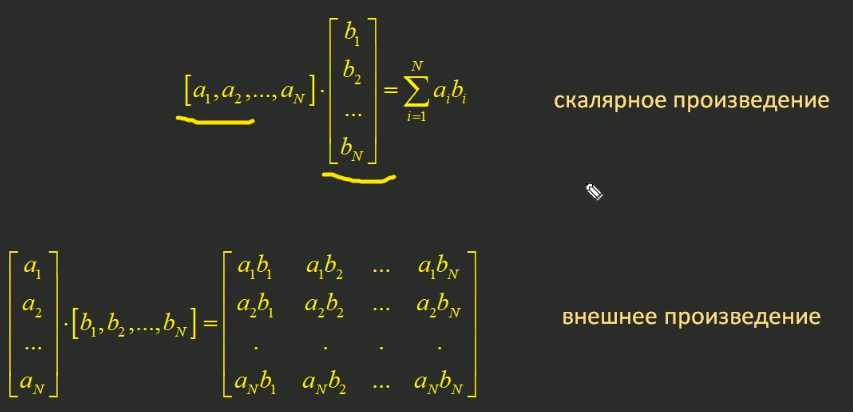

По сути нет разницы, так как [1x5]@[5x1]==[1x1],  
а [5x1]@[1x5]==[5x5]

In [108]:
a = torch.rand(5)

In [109]:
# матричное (оно еще называется внешнее)
torch.outer(a, a)

tensor([[0.6715, 0.6726, 0.3970, 0.2751, 0.4807],
        [0.6726, 0.6737, 0.3977, 0.2756, 0.4815],
        [0.3970, 0.3977, 0.2348, 0.1627, 0.2842],
        [0.2751, 0.2756, 0.1627, 0.1127, 0.1970],
        [0.4807, 0.4815, 0.2842, 0.1970, 0.3441]])

In [115]:
# аналогично
a.view(-1, 1) @ a.view(1, -1)

tensor([[0.6715, 0.6726, 0.3970, 0.2751, 0.4807],
        [0.6726, 0.6737, 0.3977, 0.2756, 0.4815],
        [0.3970, 0.3977, 0.2348, 0.1627, 0.2842],
        [0.2751, 0.2756, 0.1627, 0.1127, 0.1970],
        [0.4807, 0.4815, 0.2842, 0.1970, 0.3441]])

In [116]:
# скалярное
a.dot(a)

tensor(2.0368)

In [118]:
# аналогично
a@a

tensor(2.0368)

**Умножение матрицы на вектор или вектора на матрицу**

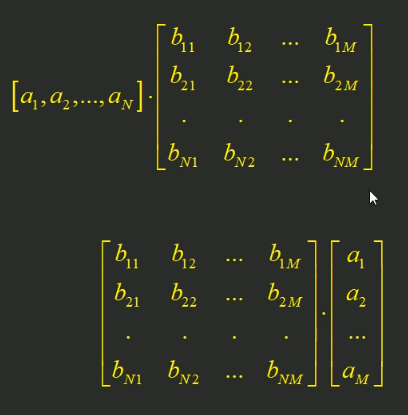

In [133]:
a = torch.arange(12).view(3, -1) # dim=3x4
b = torch.arange(4) # dim=4
print(a.shape, b.shape)
print(a, b)

torch.Size([3, 4]) torch.Size([4])
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]]) tensor([0, 1, 2, 3])


In [134]:
# Mатрица на Vектор
# [3x4]*[3] == [3x4]*[4] = [3]
a.mv(b)

tensor([14, 38, 62])

In [135]:
# аналогично
a@b

tensor([14, 38, 62])

По сути в этой команде нет необходимости

решение СЛАУ  
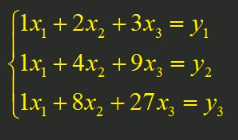

In [55]:
a = torch.tensor([1,2,3,1,4,9,1,8,27]).view(3, -1).float()
a

tensor([[ 1.,  2.,  3.],
        [ 1.,  4.,  9.],
        [ 1.,  8., 27.]])

In [56]:
# вычслим ранг. Если равен размеру матрицы, значит линейныхкомбинаций нет
torch.linalg.matrix_rank(a)

tensor(3)

In [57]:
# определим вектор таргетов

In [61]:
y = torch.tensor([10, 20, 30], dtype=torch.float32)

In [63]:
roots = torch.linalg.solve(a, y)
roots

tensor([-5.0000, 10.0000, -1.6667])

In [65]:
# проверяем
a.mv(roots)

tensor([10.0000, 20.0000, 30.0000])

есть еще одно решение - через обратную матрицу  
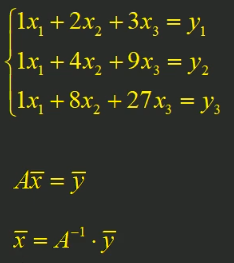

In [66]:
inv_a = torch.linalg.inv(a)
inv_a

tensor([[ 3.0000, -2.5000,  0.5000],
        [-1.5000,  2.0000, -0.5000],
        [ 0.3333, -0.5000,  0.1667]])

In [68]:
roots = inv_a.mv(y)
roots

tensor([-5.0000, 10.0000, -1.6667])

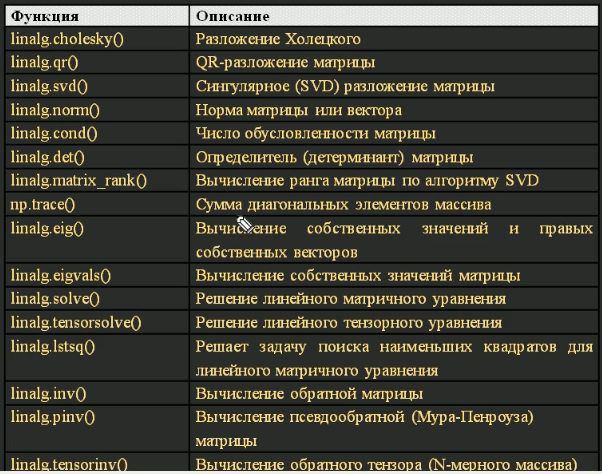

In [77]:
import torch

x = torch.rand(2, 7)
y = torch.rand(7)

torch.mv(x, y)

tensor([2.5846, 2.6315])

In [79]:
torch.mm(x, y)

RuntimeError: mat2 must be a matrix